# Data Quality Checks

## Objective

Notebook 02 membuktikan **bentuk** relasi antar tabel. Notebook ini memeriksa **isi** datanya, untuk memutuskan aturan bisnis dan aturan pembersihan yang akan ditulis di `agents.md` dan dipakai agent.

Setiap pengecekan terdiri dari: pertanyaan, kode, lalu kesimpulan yang diisi setelah output keluar. Jika suatu temuan lebih mudah dilihat secara visual, ditambahkan grafik, dan angka detailnya tetap dicetak.

| # | Pengecekan | Keputusan yang dipengaruhi |
|---|---|---|
| 1 | Order tanpa item | Apakah order tanpa item dikeluarkan dari analisis penjualan |
| 2 | Order tanpa payment | Cara menangani 1 order tersebut |
| 3 | Payment vs item | Definisi revenue |
| 4 | Urutan timestamp | Validitas metrik keterlambatan pengiriman |
| 5 | Status vs timestamp | Konsistensi status order |
| 6 | Cakupan periode | Bulan yang tidak boleh dibandingkan |
| 7 | Review ganda | Aturan memilih 1 review per order |
| 8 | Payment aneh | Aturan filter payment |
| 9 | Harga item | Validitas `price` dan `freight_value` |
| 10 | Geolocation | Cara membuat 1 baris per zip |

# 1. Load Dataset

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path('../dataset')

In [21]:
sellers = pd.read_csv(data_dir / "olist_sellers_dataset.csv")
customers = pd.read_csv(data_dir / "olist_customers_dataset.csv")
products = pd.read_csv(data_dir / "olist_products_dataset.csv")
geolocation = pd.read_csv(data_dir / "olist_geolocation_dataset.csv")
orders = pd.read_csv(data_dir / "olist_orders_dataset.csv")
items = pd.read_csv(data_dir / "olist_order_items_dataset.csv")
payments = pd.read_csv(data_dir / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(data_dir / "olist_order_reviews_dataset.csv")
translated_products = pd.read_csv(data_dir / "product_category_name_translation.csv")

# 2. Quality Checks

## Check 1: Order tanpa item

Pertanyaan: 775 order di `Orders` tidak punya item. Apa status order tersebut? Jika hampir semuanya `canceled`/`unavailable`, wajar tidak punya item dan aman dikeluarkan dari analisis penjualan.

In [22]:
orders["has_items"] = orders["order_id"].isin(items["order_id"])

print("Status of orders WITHOUT items:")
print(orders.loc[~orders["has_items"], "order_status"].value_counts())
print()
print("Share of orders without items, per status:")
(1 - orders.groupby("order_status")["has_items"].mean()).round(3)

Status of orders WITHOUT items:
order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

Share of orders without items, per status:


order_status
approved       0.000
canceled       0.262
created        1.000
delivered      0.000
invoiced       0.006
processing     0.000
shipped        0.001
unavailable    0.990
Name: has_items, dtype: float64

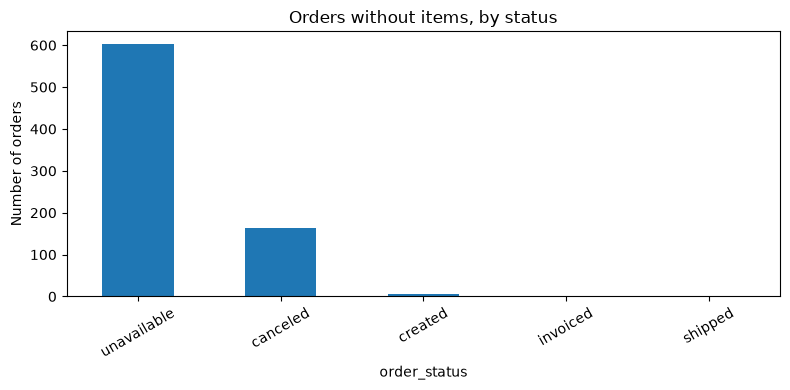

In [23]:
no_items_status = orders.loc[~orders["has_items"], "order_status"].value_counts()

ax = no_items_status.plot(kind="bar", figsize=(8, 4))
ax.set_title("Orders without items, by status")
ax.set_ylabel("Number of orders")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Temuan:** dari 775 order tanpa item, 603 berstatus `unavailable` (99% dari seluruh order `unavailable`), 164 `canceled` (26% dari seluruh order `canceled`), 5 `created`, 2 `invoiced`, dan 1 `shipped`. Tidak ada order `delivered` yang tanpa item.

**Keputusan:** order tanpa item bukan penjualan, dan aman dikeluarkan dari analisis penjualan. Dengan filter `delivered`, tidak ada order yang hilang karena item kosong. Tiga order `invoiced`/`shipped` tanpa item tidak dijelaskan oleh pola ini dan dibiarkan apa adanya (jumlahnya sangat kecil).

## Check 2: Order tanpa payment

Pertanyaan: 1 order tidak punya payment. Apa statusnya, dan apakah order itu punya item?

In [24]:
no_payment = orders[~orders["order_id"].isin(payments["order_id"])]
no_payment[["order_id", "order_status", "has_items"]]

,order_id,order_status,has_items
30710,bfbd0f9bdef84302105ad712db648a6c,delivered,True


**Temuan:** satu-satunya order tanpa payment (`bfbd0f9b...`) berstatus `delivered` dan punya item.

**Keputusan:** revenue dihitung dari tabel `items` (`price`), bukan dari `payments`, supaya order ini tetap terhitung. Order ini hanya akan tampak kurang jika agent menjumlahkan `payment_value`.

## Check 3: Payment vs item

Pertanyaan: apakah total yang dibayar pelanggan (`SUM(payment_value)`) sama dengan `SUM(price + freight_value)` per order? Jika sama, definisi "pelanggan membayar barang + ongkir" terbukti. Selisih yang ada perlu dijelaskan (misalnya voucher atau bunga cicilan).

In [25]:
paid = payments.groupby("order_id")["payment_value"].sum().rename("paid")
item_total = (items.assign(item_total=items["price"] + items["freight_value"])
                   .groupby("order_id")["item_total"].sum())

recon = pd.concat([paid, item_total], axis=1).dropna()
recon["diff"] = recon["paid"] - recon["item_total"]
recon["mismatch"] = recon["diff"].abs() > 0.01

print(f"Orders compared: {len(recon)}")
print(f"Orders with |diff| > 0.01: {recon['mismatch'].sum()} ({recon['mismatch'].mean():.2%})")
recon["diff"].describe()

Orders compared: 98665
Orders with |diff| > 0.01: 378 (0.38%)


count    98665.000000
mean         0.029092
std          1.129221
min        -51.620000
25%          0.000000
50%          0.000000
75%          0.000000
max        182.810000
Name: diff, dtype: float64

In [26]:
# Where do the differences come from?
pay_info = payments.groupby("order_id").agg(
    n_payments=("payment_value", "size"),
    max_installments=("payment_installments", "max"),
    has_voucher=("payment_type", lambda s: (s == "voucher").any()),
)
check = recon.join(pay_info)

print("Mismatch rate by has_voucher:")
print(check.groupby("has_voucher")["mismatch"].mean().round(3))
print()
print("Mismatch rate by installments > 1:")
print(check.groupby(check["max_installments"] > 1)["mismatch"].mean().round(3))

Mismatch rate by has_voucher:
has_voucher
False    0.004
True     0.003
Name: mismatch, dtype: float64

Mismatch rate by installments > 1:
max_installments
False    0.001
True     0.006
Name: mismatch, dtype: float64


Mismatched orders: 378 | paid more than item total: 290 | paid less: 88


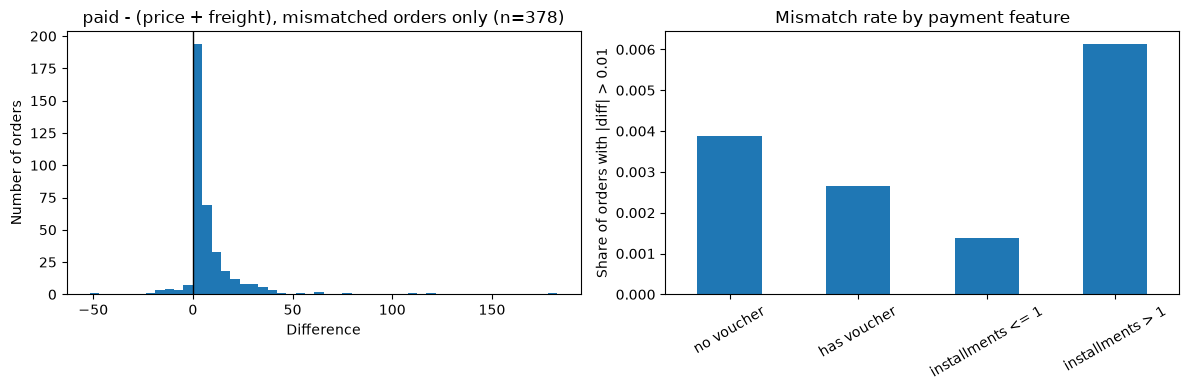

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: distribution of the difference, only for orders that actually mismatch
mismatched = recon.loc[recon["mismatch"], "diff"]
print(f"Mismatched orders: {len(mismatched)} | paid more than item total: {(mismatched > 0).sum()} | paid less: {(mismatched < 0).sum()}")
axes[0].hist(mismatched, bins=50)
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_title(f"paid - (price + freight), mismatched orders only (n={len(mismatched)})")
axes[0].set_xlabel("Difference")
axes[0].set_ylabel("Number of orders")

# Right: mismatch rate by payment feature
has_voucher = check["has_voucher"].astype(bool)
multi_inst = check["max_installments"] > 1
rates = pd.Series({
    "no voucher": check.loc[~has_voucher, "mismatch"].mean(),
    "has voucher": check.loc[has_voucher, "mismatch"].mean(),
    "installments <= 1": check.loc[~multi_inst, "mismatch"].mean(),
    "installments > 1": check.loc[multi_inst, "mismatch"].mean(),
})
rates.plot(kind="bar", ax=axes[1])
axes[1].set_title("Mismatch rate by payment feature")
axes[1].set_ylabel("Share of orders with |diff| > 0.01")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

**Temuan:** dari 98.665 order yang bisa dibandingkan, 378 (0,38%) berbeda lebih dari 0,01, dan selisih median adalah 0. Artinya pelanggan membayar `price + freight_value`. Selisih bisa positif maupun negatif (min -51,62; maks 182,81), jadi bukan satu pola tunggal. Tingkat selisih pada voucher dan non-voucher hampir sama (0,3% vs 0,4%), sedangkan cicilan > 1 sedikit lebih tinggi (0,6% vs 0,1%), tetapi semuanya kecil.

**Keputusan:** definisi di bawah ini didukung data.
- Revenue (GMV) = `SUM(price)`.
- Ongkir = `SUM(freight_value)`, dilaporkan terpisah.
- Total dibayar pelanggan = `price + freight_value`.

Penyebab 378 selisih tidak terbukti. Dugaan bunga cicilan masuk akal, tapi tidak menjelaskan selisih negatif, jadi tidak ditulis sebagai fakta.

## Check 4: Urutan timestamp

Pertanyaan: apakah ada order yang urutan waktunya tidak masuk akal (misalnya dikirim sebelum dibeli)? Ini menentukan apakah metrik seperti "lama pengiriman" atau "persen terlambat" bisa dipercaya.

In [28]:
ts_cols = ["order_purchase_timestamp", "order_approved_at",
           "order_delivered_carrier_date", "order_delivered_customer_date",
           "order_estimated_delivery_date"]

orders_ts = orders.copy()
for col in ts_cols:
    orders_ts[col] = pd.to_datetime(orders_ts[col])

print("approved before purchase:", (orders_ts["order_approved_at"] < orders_ts["order_purchase_timestamp"]).sum())
print("carrier pickup before purchase:", (orders_ts["order_delivered_carrier_date"] < orders_ts["order_purchase_timestamp"]).sum())
print("carrier pickup before approval:", (orders_ts["order_delivered_carrier_date"] < orders_ts["order_approved_at"]).sum())
print("customer delivery before carrier pickup:", (orders_ts["order_delivered_customer_date"] < orders_ts["order_delivered_carrier_date"]).sum())
print("customer delivery before purchase:", (orders_ts["order_delivered_customer_date"] < orders_ts["order_purchase_timestamp"]).sum())

approved before purchase: 0
carrier pickup before purchase: 166
carrier pickup before approval: 1359
customer delivery before carrier pickup: 23
customer delivery before purchase: 0


**Temuan:** tidak ada order yang disetujui atau dikirim ke pelanggan sebelum dibeli (0 kasus). Namun 166 order diambil kurir sebelum tanggal pembelian, 23 order sampai ke pelanggan sebelum diambil kurir, dan 1.359 order diambil kurir sebelum disetujui.

**Keputusan:** metrik pengiriman memakai `order_delivered_customer_date` terhadap `order_purchase_timestamp` dan `order_estimated_delivery_date`, karena tidak ada anomali di pasangan itu. Metrik berbasis `order_delivered_carrier_date` (misalnya waktu proses seller) dikecualikan dari agent versi pertama. Kasus 166 dan 23 jelas tidak mungkin. Kasus 1.359 (kurir sebelum approval) mencurigakan, tapi belum tentu salah.

## Check 5: Status vs timestamp

Pertanyaan: apakah status order konsisten dengan kolom tanggalnya? Order `delivered` seharusnya punya tanggal sampai ke pelanggan, dan order selain `delivered` seharusnya tidak.

In [29]:
is_delivered = orders_ts["order_status"] == "delivered"
has_delivery_date = orders_ts["order_delivered_customer_date"].notna()

print("delivered but no delivered_customer_date:", (is_delivered & ~has_delivery_date).sum())
print("not delivered but has delivered_customer_date:", (~is_delivered & has_delivery_date).sum())
print()
print("Status of the second group:")
print(orders_ts.loc[~is_delivered & has_delivery_date, "order_status"].value_counts())

delivered but no delivered_customer_date: 8
not delivered but has delivered_customer_date: 6

Status of the second group:
order_status
canceled    6
Name: count, dtype: int64


**Temuan:** 8 order `delivered` tidak punya tanggal sampai, dan 6 order bertanggal sampai tetapi berstatus `canceled`.

**Keputusan:** untuk metrik pengiriman, order harus `delivered` dan `order_delivered_customer_date` tidak kosong (8 order dibuang). Enam order `canceled` bertanggal sampai tidak dihitung sebagai pengiriman.

## Check 6: Cakupan periode

Pertanyaan: pada bulan apa saja data lengkap? Bulan dengan jumlah order sangat kecil (awal dan akhir dataset) akan menyesatkan jika dibandingkan dengan bulan lain.

In [30]:
print("First purchase:", orders_ts["order_purchase_timestamp"].min())
print("Last purchase:", orders_ts["order_purchase_timestamp"].max())
print()
orders_ts["order_purchase_timestamp"].dt.to_period("M").value_counts().sort_index()

First purchase: 2016-09-04 21:15:19
Last purchase: 2018-10-17 17:30:18



order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64

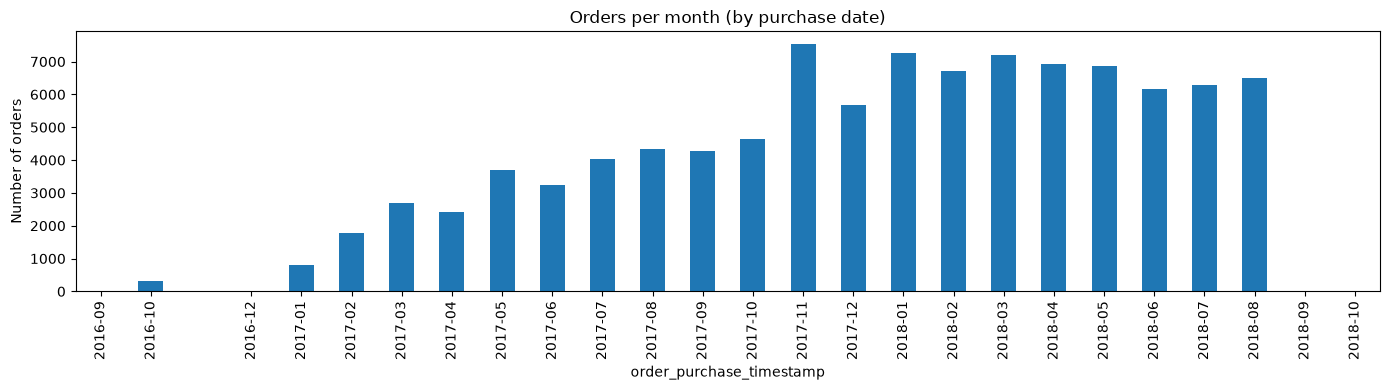

In [31]:
monthly = orders_ts["order_purchase_timestamp"].dt.to_period("M").value_counts().sort_index()

ax = monthly.plot(kind="bar", figsize=(14, 4))
ax.set_title("Orders per month (by purchase date)")
ax.set_ylabel("Number of orders")
plt.tight_layout()
plt.show()

**Temuan:** data berjalan dari 2016-09-04 sampai 2018-10-17. Bulan awal dan akhir sangat tipis: 2016-09 (4 order), 2016-10 (324), 2016-12 (1), 2018-09 (16), 2018-10 (4). Bulan 2016-11 tidak ada sama sekali, dan tidak terlihat di tabel karena `value_counts` tidak menampilkan bulan kosong. Mulai 2017-01 (800) sampai 2018-08 (6.512) datanya berkelanjutan dan tumbuh, dengan puncak 2017-11 (7.544).

**Keputusan:** jendela analisis bawaan adalah 2017-01 sampai 2018-08. Jika pengguna bertanya tentang 2016 atau September-Oktober 2018, agent wajib memberi peringatan bahwa datanya tidak lengkap. Perbandingan bulan ke bulan di awal 2017 mencerminkan pertumbuhan marketplace, bukan hanya perubahan perilaku.

## Check 7: Review ganda

Pertanyaan: untuk order yang punya lebih dari satu review, bagaimana cara memilih satu? Kandidat aturan: ambil review dengan `review_answer_timestamp` paling baru. Aturan itu hanya aman jika tidak ada timestamp yang sama.

In [32]:
n_reviews = reviews.groupby("order_id")["review_id"].transform("size")
multi_reviews = reviews[n_reviews > 1].sort_values(["order_id", "review_answer_timestamp"])

multi_reviews[["order_id", "review_id", "review_score",
               "review_creation_date", "review_answer_timestamp"]].head(10)

,order_id,review_id,review_score,review_creation_date,review_answer_timestamp
22423,0035246a40f520710769010f752e7507,2a74b0559eb58fc1ff842ecc999594cb,5,2017-08-25 00:00:00,2017-08-29 21:45:57
25612,0035246a40f520710769010f752e7507,89a02c45c340aeeb1354a24e7d4b2c1e,5,2017-08-29 00:00:00,2017-08-30 01:59:12
22779,013056cfe49763c6f66bda03396c5ee3,ab30810c29da5da8045216f0f62652a2,5,2018-02-22 00:00:00,2018-02-23 12:12:30
68633,013056cfe49763c6f66bda03396c5ee3,73413b847f63e02bc752b364f6d05ee9,4,2018-03-04 00:00:00,2018-03-05 17:02:00
854,0176a6846bcb3b0d3aa3116a9a768597,830636803620cdf8b6ffaf1b2f6e92b2,5,2017-12-30 00:00:00,2018-01-02 10:54:06
83224,0176a6846bcb3b0d3aa3116a9a768597,d8e8c42271c8fb67b9dad95d98c8ff80,5,2017-12-30 00:00:00,2018-01-02 10:54:47
89888,02355020fd0a40a0d56df9f6ff060413,0c8e7347f1cdd2aede37371543e3d163,3,2018-03-21 00:00:00,2018-03-22 01:32:08
17582,02355020fd0a40a0d56df9f6ff060413,017f0e1ea6386de662cbeba299c59ad1,1,2018-03-29 00:00:00,2018-03-30 03:16:19
37911,029863af4b968de1e5d6a82782e662f5,04d945e95c788a3aa1ffbee42105637b,5,2017-07-14 00:00:00,2017-07-17 13:58:06
55137,029863af4b968de1e5d6a82782e662f5,61fe4e7d1ae801bbe169eb67b86c6eda,4,2017-07-19 00:00:00,2017-07-20 12:06:11


In [33]:
# Is "latest answer timestamp" a safe rule?
ties = reviews.groupby("order_id")["review_answer_timestamp"].apply(lambda s: s.duplicated(keep=False).any())
score_spread = reviews.groupby("order_id")["review_score"].nunique()
orders_per_review_id = reviews.groupby("review_id")["order_id"].nunique()

print("Orders with tied review_answer_timestamp:", ties.sum())
print("Orders whose reviews have more than 1 distinct score:", (score_spread > 1).sum())
print("review_id attached to more than 1 order:", (orders_per_review_id > 1).sum())

Orders with tied review_answer_timestamp: 0
Orders whose reviews have more than 1 distinct score: 202
review_id attached to more than 1 order: 789


**Temuan:** tidak ada timestamp jawaban yang kembar, jadi aturan "ambil review dengan `review_answer_timestamp` terbaru" menghasilkan satu pilihan pasti. Aturan ini penting karena 202 order punya review dengan skor berbeda. Selain itu 789 `review_id` terpasang pada lebih dari satu order.

**Keputusan:** satu review per order = review dengan `review_answer_timestamp` paling baru. Jangan menghitung review dengan `COUNT(DISTINCT review_id)`. Gunakan order sebagai satuan, karena `review_id` bukan key.

## Check 8: Payment aneh

Pertanyaan: ada payment bernilai 0 atau bertipe `not_defined`. Apakah perlu difilter, dan apakah terkait voucher?

In [34]:
print("payment_value == 0 by payment_type:")
print(payments.loc[payments["payment_value"] == 0, "payment_type"].value_counts())
print()
print("payment_type == 'not_defined':")
print(payments[payments["payment_type"] == "not_defined"])
print()
print("payment_installments == 0:", (payments["payment_installments"] == 0).sum())

payment_value == 0 by payment_type:
payment_type
voucher        6
not_defined    3
Name: count, dtype: int64

payment_type == 'not_defined':
                               order_id  payment_sequential payment_type  \
51280  4637ca194b6387e2d538dc89b124b0ee                   1  not_defined   
57411  00b1cb0320190ca0daa2c88b35206009                   1  not_defined   
94427  c8c528189310eaa44a745b8d9d26908b                   1  not_defined   

       payment_installments  payment_value  
51280                     1            0.0  
57411                     1            0.0  
94427                     1            0.0  

payment_installments == 0: 2


**Temuan:** ada 9 payment bernilai 0: 6 `voucher` dan 3 `not_defined`. Ketiga `not_defined` bernilai 0 dan bercicilan 1. Dua payment punya `payment_installments = 0`.

**Keputusan:** baris `not_defined` dikeluarkan saat menghitung distribusi tipe pembayaran. Status order pada baris-baris ini belum dicek. Karena revenue dihitung dari `items`, baris payment bernilai 0 tidak memengaruhi angka revenue.

## Check 9: Harga item

Pertanyaan: apakah `price` dan `freight_value` memiliki nilai yang tidak masuk akal (nol atau negatif)? `price` adalah dasar revenue, jadi harus valid.

In [35]:
print("price <= 0:", (items["price"] <= 0).sum())
print("freight_value < 0:", (items["freight_value"] < 0).sum())
print("freight_value == 0:", (items["freight_value"] == 0).sum())
items[["price", "freight_value"]].describe()

price <= 0: 0
freight_value < 0: 0
freight_value == 0: 383


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


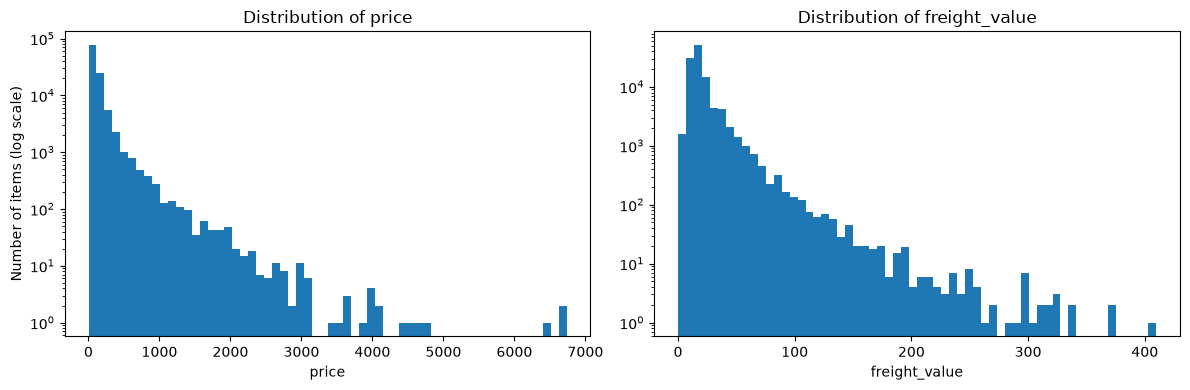

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(items["price"], bins=60)
axes[0].set_yscale("log")
axes[0].set_title("Distribution of price")
axes[0].set_xlabel("price")
axes[0].set_ylabel("Number of items (log scale)")

axes[1].hist(items["freight_value"], bins=60)
axes[1].set_yscale("log")
axes[1].set_title("Distribution of freight_value")
axes[1].set_xlabel("freight_value")

plt.tight_layout()
plt.show()

**Temuan:** tidak ada `price` <= 0 maupun `freight_value` negatif. Harga berkisar 0,85 sampai 6.735, dengan ekor kanan panjang (rata-rata 120,65 vs median 74,99). Ada 383 item dengan ongkir 0 (0,3%).

**Keputusan:** `price` valid sebagai dasar revenue. Ongkir 0 dianggap sah (kemungkinan gratis ongkir, ini dugaan, bukan hasil cek). Untuk "harga tipikal" agent sebaiknya memakai median, bukan rata-rata, karena distribusinya miring.

## Check 10: Geolocation

Pertanyaan: sebelum diagregasi menjadi 1 baris per zip, apakah koordinatnya valid? Batas di bawah adalah bounding box kasar Brasil (lat -34 s/d 6, lng -74 s/d -34), bukan batas resmi. Selain itu, apakah satu zip bisa mencakup lebih dari satu state?

In [37]:
lat_ok = geolocation["geolocation_lat"].between(-34, 6)
lng_ok = geolocation["geolocation_lng"].between(-74, -34)
states_per_zip = geolocation.groupby("geolocation_zip_code_prefix")["geolocation_state"].nunique()

print("Rows outside Brazil bounding box:", (~(lat_ok & lng_ok)).sum())
print("Zip code prefixes mapped to more than 1 state:", (states_per_zip > 1).sum())

Rows outside Brazil bounding box: 42
Zip code prefixes mapped to more than 1 state: 8


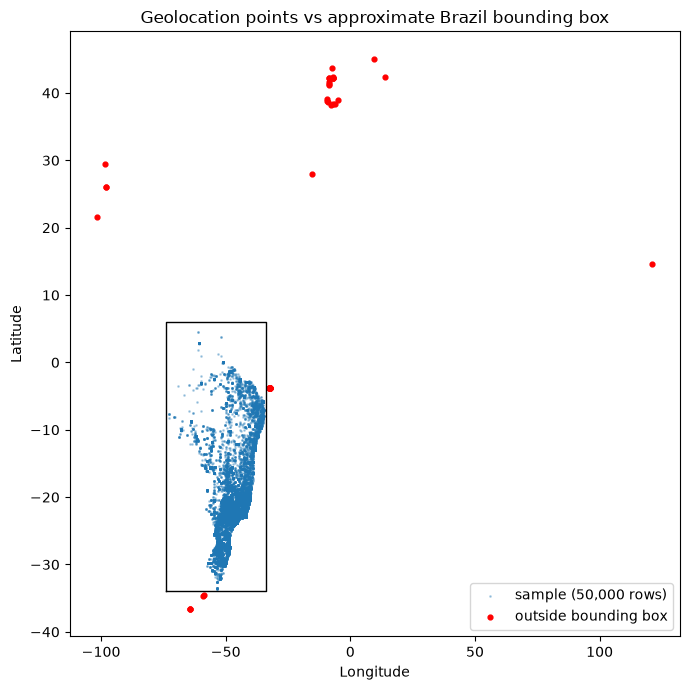

In [38]:
sample = geolocation.sample(50000, random_state=42)
outside = geolocation[~(lat_ok & lng_ok)]

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(sample["geolocation_lng"], sample["geolocation_lat"], s=1, alpha=0.3, label="sample (50,000 rows)")
ax.scatter(outside["geolocation_lng"], outside["geolocation_lat"], s=12, color="red", label="outside bounding box")
ax.plot([-74, -34, -34, -74, -74], [-34, -34, 6, 6, -34], color="black", linewidth=1)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Geolocation points vs approximate Brazil bounding box")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Temuan:** 42 dari 1.000.163 baris berada di luar bounding box kasar Brasil. Grafik menunjukkan sebagian jelas salah letak (Amerika Utara, Eropa, Asia, Argentina). Sekelompok titik tepat di tepi timur kotak (sekitar lng -33, lat -4) kemungkinan pulau Fernando de Noronha, jadi bisa sah dan hanya terpotong oleh kotak saya yang terlalu sempit di timur (ini dugaan). Ada 8 zip yang terpetakan ke lebih dari satu state.

**Keputusan:** `geo_per_zip` memakai median `lat` dan `lng` per zip, yang tahan terhadap 42 titik ganjil, dan modus untuk state. Batas timur kotak perlu dilebarkan (misalnya ke -28) jika baris luar dipakai sebagai filter. Delapan zip multi-state ditandai sebagai berkualitas rendah.

# 3. Rangkuman Keputusan

Tabel ini menjadi bahan utama `agents.md`.

| # | Temuan | Aturan yang dipakai agent |
|---|---|---|
| 1 | 775 order tanpa item, hampir semuanya `unavailable`/`canceled`/`created`; tidak ada `delivered` | Keluarkan dari analisis penjualan; filter `delivered` sudah cukup |
| 2 | 1 order `delivered` tanpa payment | Revenue dihitung dari `items`, bukan `payments` |
| 3 | Pelanggan membayar `price + freight`; 0,38% order berselisih | Revenue (GMV) = `SUM(price)`; ongkir dilaporkan terpisah |
| 4 | Tanggal kurir tidak konsisten (166, 23, 1.359 kasus); pasangan purchase/delivered/estimated bersih | Metrik pengiriman hanya memakai tanggal purchase, delivered_customer, dan estimated |
| 5 | 8 `delivered` tanpa tanggal sampai; 6 `canceled` bertanggal sampai | Metrik pengiriman butuh `delivered` dan tanggal sampai tidak kosong |
| 6 | Data lengkap hanya 2017-01 sampai 2018-08 | Jendela bawaan 2017-01 s/d 2018-08; beri peringatan di luar itu |
| 7 | Review ganda per order; tidak ada timestamp kembar; `review_id` bukan key | 1 review per order = `review_answer_timestamp` terbaru; hitung per order |
| 8 | 9 payment bernilai 0; 3 bertipe `not_defined` | Keluarkan `not_defined` dari distribusi tipe pembayaran |
| 9 | Harga dan ongkir valid; distribusi miring ke kanan; 383 ongkir 0 | Pakai median untuk harga tipikal; ongkir 0 dianggap sah |
| 10 | 42 koordinat di luar Brasil; 8 zip multi-state | `geo_per_zip` = median lat/lng, modus state; lebarkan batas timur jika memfilter |